In [15]:
import os
# Clone thư viện aima-python nếu chưa có
if not os.path.exists('aima-python'):
    !git clone https://github.com/aimacode/aima-python.git

# Thêm thư mục vào hệ thống dẫn để Python có thể import trực tiếp
import sys
sys.path.insert(0, os.path.abspath('aima-python'))

In [16]:
# Thay thế %run bootstrap.ipynb bằng import trực tiếp và các thiết lập
import sys
import os
sys.path.insert(0, os.path.abspath('aima-python'))


# BÀI TOÁN THỎA MÃN RÀNG BUỘC (CONSTRAINT SATISFACTION PROBLEMS - CSP)

Notebook IPy này đóng vai trò là tài liệu hỗ trợ cho các chủ đề được đề cập trong **Chương 6: Bài toán thỏa mãn ràng buộc** của cuốn sách *Artificial Intelligence: A Modern Approach*. Chúng ta sẽ sử dụng các cài đặt có sẵn trong module **csp.py**. Mặc dù notebook này có tóm tắt ngắn gọn các chủ đề chính, bạn vẫn nên làm quen trước với các nội dung trong sách. Chúng ta sẽ cùng xem một số minh họa trực quan và giải quyết một vài bài toán CSP được mô tả trong sách. Hãy bắt đầu bằng cách import mọi thứ từ module csp.

In [17]:
from aima.csp import *
from aima.notebook_utils import psource, plot_NQueens
%matplotlib inline

# Hide warnings in the matplotlib sections
import warnings
warnings.filterwarnings("ignore")

## MỤC LỤC

* Tổng quan (Overview)
* Tô màu đồ thị (Graph Coloring)
* Bài toán N-Queens (N-Queens)
* Thuật toán AC-3
* Tìm kiếm quay lui (Backtracking Search)
* Bộ giải Tree CSP (Tree CSP Solver)
* Trực quan hóa tô màu đồ thị
* Trực quan hóa bài toán N-Queens

## TỔNG QUAN

CSPs là một dạng đặc biệt của các bài toán tìm kiếm. Ở đây, chúng ta không coi không gian trạng thái là một chiếc hộp đen (black box), mà mỗi trạng thái có một cấu trúc cụ thể. Chúng ta tận dụng điều này để tinh chỉnh các thuật toán sao cho phù hợp nhất với bài toán.

Một trạng thái CSP được định nghĩa bởi một tập hợp các biến, mỗi biến nhận các giá trị từ miền giá trị tương ứng. Các biến này chỉ có thể nhận một số giá trị nhất định để thỏa mãn các ràng buộc đề ra. Một tập hợp các phép gán thỏa mãn tất cả các ràng buộc sẽ vượt qua kiểm tra mục tiêu (goal test). Hãy bắt đầu bằng cách khám phá lớp `CSP` dùng để mô hình hóa các bài toán CSP của chúng ta.

In [18]:
psource(CSP)

Các tham số của phương thức khởi tạo `__init__` xác định bài toán CSP. Các biến (`variables`) có thể được truyền dưới dạng một danh sách các chuỗi hoặc số nguyên. Các miền giá trị (`domains`) được truyền dưới dạng một dictionary (kiểu dữ liệu từ điển) trong đó "khóa" (key) chỉ định các biến và "giá trị" (value) chỉ định các miền giá trị tương ứng. Biến cũng có thể được truyền dưới dạng một danh sách rỗng, khi đó các biến sẽ được tự động trích xuất từ các khóa của dictionary miền giá trị.

Tham số láng giềng (`neighbors`) là một từ điển của các biến, mô tả đồ thị ràng buộc. Ở đây, mỗi khóa (biến) sẽ có một danh sách các giá trị là các biến có ràng buộc trực tiếp với nó. Tham số ràng buộc (`constraint`) phải là một hàm dạng **f(A, a, B, b)** trả về **True** nếu các láng giềng A, B **thỏa mãn ràng buộc** khi chúng có giá trị lần lượt là **A=a, B=b**.

Chúng ta cũng có các tham số bổ sung như `nassigns` để đếm số lần gán giá trị được thực hiện mỗi khi gọi phương thức `assign`. Bạn có thể đọc thêm về các phương thức và tham số này trong chuỗi tài liệu (docstring) của lớp. Chúng ta sẽ thảo luận chi tiết hơn khi gặp chúng trong các ví dụ thực tế. Hãy bắt đầu ngay với một ví dụ.

## TÔ MÀU ĐỒ THỊ (GRAPH COLORING)

Chúng ta sử dụng bài toán tô màu đồ thị làm ví dụ xuyên suốt để minh họa các thuật toán khác nhau trong **module csp**. Ý tưởng của bài toán tô màu bản đồ là các đỉnh kề nhau (được nối bởi một cạnh) không được có cùng màu trên toàn bộ đồ thị. Đồ thị có thể được tô bằng một số lượng màu cố định. Ở đây, mỗi đỉnh là một biến và các giá trị là các màu có thể được gán cho chúng.

Vì miền giá trị (các màu sắc) giống nhau cho tất cả các đỉnh, chúng ta sử dụng một từ điển tùy chỉnh được định nghĩa bởi lớp **UniversalDict**. Lớp **UniversalDict** nhận vào một tham số và trả về tham số đó làm giá trị cho mọi khóa được truy vấn trong từ điển. Nó rất giống với **defaultdict** trong Python ngoại trừ việc nó không hỗ trợ việc gán giá trị cho từng phần tử riêng lẻ.

In [19]:
s = UniversalDict(['R','G','B'])
s[5]

['R', 'G', 'B']

Đối với CSP của mình, chúng ta cũng cần xác định một hàm ràng buộc **f(A, a, B, b)**. Trong đó, chúng ta cần đảm bảo các đỉnh kề nhau không có cùng màu. Ràng buộc này được định nghĩa sẵn trong hàm **different_values_constraint** của module.

In [20]:
psource(different_values_constraint)

Lớp CSP nhận đầu vào các đỉnh láng giềng dưới dạng một Dict. Module cung cấp một hàm trợ giúp đơn giản tên là **parse_neighbors** cho phép chúng ta nhập dữ liệu dưới dạng chuỗi văn bản và trả về một Dict có định dạng tương thích với **Lớp CSP**.

In [21]:
%pdoc parse_neighbors

Hàm **MapColoringCSP** khởi tạo và trả về một đối tượng CSP với hàm ràng buộc và các bang đã nêu ở trên. Các biến là khóa của từ điển láng giềng và ràng buộc là ràng buộc được chỉ định bởi hàm **different_values_constraint**.

**Australia**, **USA** và **France** là ba bài toán CSP mẫu đã được tạo sẵn bằng cách sử dụng **MapColoringCSP**. Bản đồ **Australia** tương ứng với **Hình 6.1** trong sách giáo khoa.

In [22]:
psource(MapColoringCSP)

In [23]:
australia_csp, usa_csp, france_csp

(<aima.csp.CSP at 0x7b3307326270>,
 <aima.csp.CSP at 0x7b330734f110>)

## BÀI TOÁN N-QUEENS

Bài toán N-queens là bài toán đặt N quân hậu trên bàn cờ kích thước N×N sao cho không có hai quân hậu nào tấn công lẫn nhau. Ở đây N là một số tự nhiên.

Tương tự như bài toán tô màu đồ thị, NQueens cũng được cài đặt trong module csp. Lớp **NQueensCSP** kế thừa từ lớp **CSP**. Nó thực hiện một số sửa đổi trong các phương thức để phù hợp với bài toán đặc thù này. Các quân hậu được giả định đặt mỗi cột một quân, từ trái sang phải. Điều đó có nghĩa là vị trí (x, y) đại diện cho (biến, giá trị) trong CSP. Ràng buộc cần truyền vào CSP được định nghĩa trong hàm **queen_constraint**. Ràng buộc được thỏa mãn (true) nếu A và B là cùng một biến, hoặc nếu chúng không nằm trên cùng một hàng, cùng đường chéo xuôi hoặc đường chéo ngược.

In [24]:
psource(queen_constraint)

Phương thức **NQueensCSP** triển khai các thuật toán hỗ trợ giải bài toán thông qua **min_conflicts**, đây là một trong nhiều kỹ thuật phổ biến để giải quyết các CSP. Vì **min_conflicts** sử dụng phương pháp leo đồi dựa trên số lượng xung đột để giải quyết, các phương thức gán giá trị **assign** và hủy gán **unassign** của CSP được sửa đổi để ghi nhận các xung đột. Chi tiết hơn về các cấu trúc: **rows** (hàng), **downs** (đường chéo xuống), **ups** (đường chéo lên) giúp ghi lại xung đột được giải thích chi tiết trong docstring.

In [25]:
psource(NQueensCSP)

Phương thức khởi tạo `__init__` chỉ nhận một tham số duy nhất là **n** - kích thước của bài toán. Để tạo một thực thể mới, chúng ta chỉ cần truyền giá trị n mong muốn vào hàm dựng.

In [26]:
eight_queens = NQueensCSP(8)

Chúng ta đã định nghĩa xong CSP.
Bây giờ, chúng ta cần giải quyết nó.

### Thuật toán Min-conflicts (Tối thiểu hóa xung đột)
Như đã đề cập ở trên, thuật toán `min_conflicts` là một phương pháp hiệu quả để giải quyết các bài toán dạng này.
<br>
Ban đầu, tất cả các biến của CSP được khởi tạo giá trị một cách _ngẫu nhiên_.
<br>
Sau đó, thuật toán sẽ chọn ngẫu nhiên một biến đang gặp xung đột và vi phạm một số ràng buộc của CSP.
<br>
Biến được chọn sau đó sẽ được gán một giá trị mới giúp _tối thiểu hóa_ số lượng xung đột.
<br>
Đây là một **thuật toán ngẫu nhiên đơn giản** hoạt động trên nguyên lý tương tự như **Leo đồi (Hill-climbing)**. Trạng thái xung đột liên tục được thay đổi thành trạng thái ít xung đột hơn nhằm tìm kiếm một lời giải tối ưu gần đúng.
<br>
Thuật toán này đôi khi sẽ hoạt động tốt hơn rất nhiều nếu có một phương án gán nhãn ban đầu tốt. Việc kết hợp các kỹ thuật tham lam để có được cấu hình ban đầu tốt, sau đó dùng `min_conflicts` để giải quyết hoàn toàn CSP có thể tăng tốc độ thực thi một cách đáng kinh ngạc, đặc biệt là đối với các bài toán CSP có không gian trạng thái cực kỳ rộng lớn.

In [27]:
psource(min_conflicts)

Hãy sử dụng thuật toán này để giải bài toán CSP xếp 8 quân hậu (`eight_queens`).

In [28]:
solution = min_conflicts(eight_queens)

Đây thực sự là một lời giải hợp lệ.
<br>
File `notebook.py` có chứa một hàm trợ giúp để trực quan hóa không gian lời giải này.

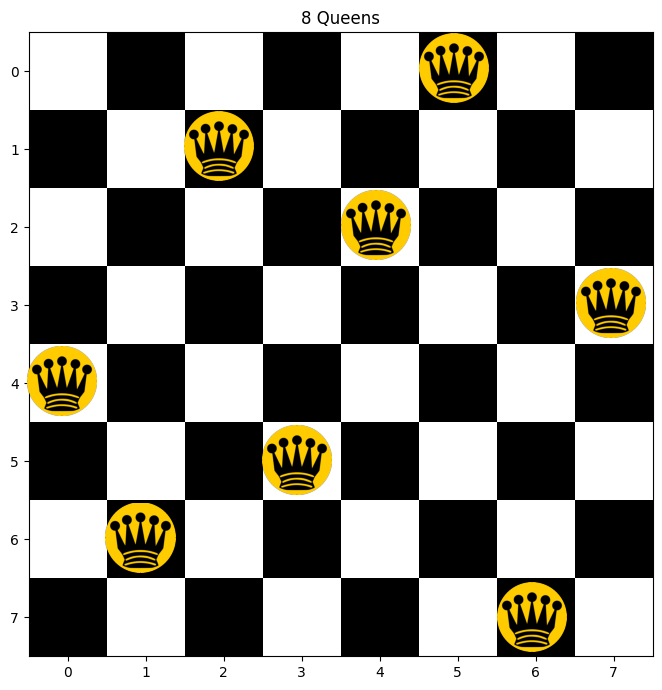

In [29]:
plot_NQueens(solution)

Hãy xem thử liệu chúng ta có thể tìm ra một lời giải khác hay không.

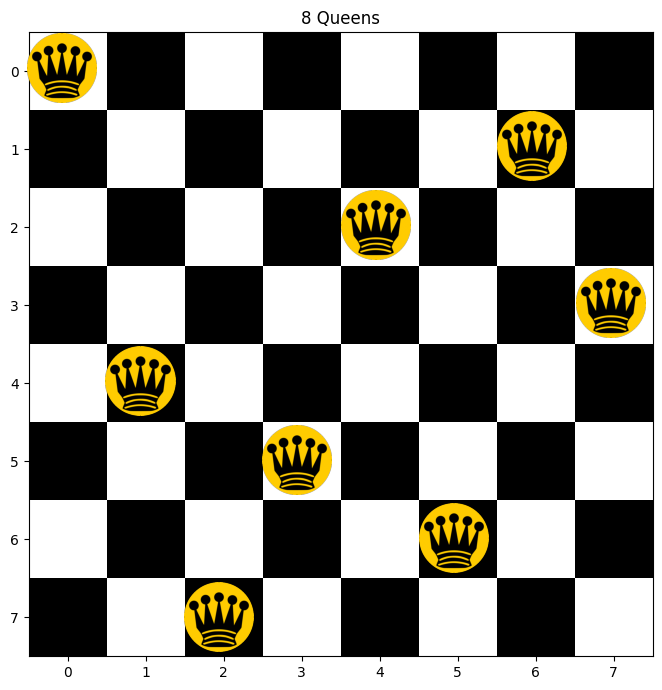

In [30]:
eight_queens = NQueensCSP(8)
solution = min_conflicts(eight_queens)
plot_NQueens(solution)

Lần này lời giải đã có một chút khác biệt.
Chạy ô lệnh phía trên nhiều lần sẽ cho bạn các kết quả hợp lệ khác nhau.
<br>
Trong notebook `search.ipynb`, chúng ta sẽ tìm hiểu cách giải quyết bài toán N-Queens bằng **phương pháp tìm kiếm heuristic** như `uniform_cost_search` (tìm kiếm chi phí đồng nhất) hay `astar_search` (tìm kiếm A*).

### Các hàm trợ giúp

Bây giờ chúng ta sẽ triển khai một vài hàm trợ giúp để trực quan hóa Bài toán Tô màu; chúng ta cũng sẽ thực hiện một số chỉnh sửa đối với các lớp và hàm hiện có để ghi nhận thêm thông tin. Đầu tiên, chúng ta sửa đổi các phương thức **assign** và **unassign** trong lớp **CSP** để lưu bản sao của quá trình gán giá trị vào danh sách lịch sử **assignment_history**. Chúng ta đặt tên cho lớp mới này là **InstruCSP**; nó sẽ cho phép chúng ta quan sát sự phát triển của các phép gán biến theo thời gian.

In [31]:
import copy
class InstruCSP(CSP):

    def __init__(self, variables, domains, neighbors, constraints):
        super().__init__(variables, domains, neighbors, constraints)
        self.assignment_history = []

    def assign(self, var, val, assignment):
        super().assign(var,val, assignment)
        self.assignment_history.append(copy.deepcopy(assignment))

    def unassign(self, var, assignment):
        super().unassign(var,assignment)
        self.assignment_history.append(copy.deepcopy(assignment))

Tiếp theo, chúng ta định nghĩa hàm **make_instru**, hàm này nhận một đối tượng của lớp **CSP** và trả về một đối tượng của lớp **InstruCSP**.

In [32]:
def make_instru(csp):
    return InstruCSP(csp.variables, csp.domains, csp.neighbors, csp.constraints)

Chúng ta sẽ sử dụng một đồ thị được định nghĩa dưới dạng từ điển phục vụ cho mục đích vẽ đồ thị trong Bài toán Tô màu Đồ thị. Các khóa là các đỉnh (nút) và giá trị tương ứng của chúng là các đỉnh kề mà chúng được kết nối trực tiếp.

In [33]:
neighbors = {
    0: [6, 11, 15, 18, 4, 11, 6, 15, 18, 4],
    1: [12, 12, 14, 14],
    2: [17, 6, 11, 6, 11, 10, 17, 14, 10, 14],
    3: [20, 8, 19, 12, 20, 19, 8, 12],
    4: [11, 0, 18, 5, 18, 5, 11, 0],
    5: [4, 4],
    6: [8, 15, 0, 11, 2, 14, 8, 11, 15, 2, 0, 14],
    7: [13, 16, 13, 16],
    8: [19, 15, 6, 14, 12, 3, 6, 15, 19, 12, 3, 14],
    9: [20, 15, 19, 16, 15, 19, 20, 16],
    10: [17, 11, 2, 11, 17, 2],
    11: [6, 0, 4, 10, 2, 6, 2, 0, 10, 4],
    12: [8, 3, 8, 14, 1, 3, 1, 14],
    13: [7, 15, 18, 15, 16, 7, 18, 16],
    14: [8, 6, 2, 12, 1, 8, 6, 2, 1, 12],
    15: [8, 6, 16, 13, 18, 0, 6, 8, 19, 9, 0, 19, 13, 18, 9, 16],
    16: [7, 15, 13, 9, 7, 13, 15, 9],
    17: [10, 2, 2, 10],
    18: [15, 0, 13, 4, 0, 15, 13, 4],
    19: [20, 8, 15, 9, 15, 8, 3, 20, 3, 9],
    20: [3, 19, 9, 19, 3, 9]
}

Hiện tại chúng ta đã sẵn sàng tạo một thực thể InstruCSP cho bài toán của mình. Chúng ta thực hiện điều này cho một đối tượng thuộc lớp **MapColoringProblem** (kế thừa từ lớp **CSP**). Điều này có nghĩa là hàm **make_instru** của chúng ta sẽ hoạt động hoàn toàn chính xác.

In [34]:
coloring_problem = MapColoringCSP('RGBY', neighbors)

In [35]:
coloring_problem1 = make_instru(coloring_problem)

### LAN TRUYỀN RÀNG BUỘC (CONSTRAINT PROPAGATION)
Các thuật toán giải quyết CSP có thể lựa chọn giữa việc tìm kiếm đơn thuần hoặc thực hiện một kỹ thuật suy diễn đặc trưng gọi là _lan truyền ràng buộc_.
Các ràng buộc có thể được sử dụng để giảm số lượng giá trị hợp lệ cho một biến khác, và hành động này lại tiếp tục thu hẹp miền giá trị của các biến kế tiếp, v.v.
<br>
Kỹ thuật lan truyền ràng buộc cố gắng thiết lập trạng thái _thỏa mãn tính nhất quán cục bộ_.
Hãy coi mỗi biến như một đỉnh trên đồ thị và mỗi ràng buộc nhị phân như một cung kết nối.
Việc áp đặt tính nhất quán cục bộ giúp loại bỏ các giá trị không thống nhất trên toàn bộ đồ thị, tương tự như thuật toán `GraphPlan` trong lập kế hoạch, nơi các liên kết loại trừ lẫn nhau (mutex links) bị loại bỏ khỏi đồ thị kế hoạch.

Có nhiều mức độ nhất quán cục bộ khác nhau:
1. Nhất quán nút (Node consistency)
2. Nhất quán cung (Arc consistency)
3. Nhất quán đường đi (Path consistency)
4. Nhất quán K (K-consistency)
5. Ràng buộc toàn cục (Global constraints)

Hãy tham khảo **mục 6.2** trong sách để biết thêm chi tiết.
<br>

## THUẬT TOÁN AC-3
Trước khi tìm hiểu sâu về AC-3, chúng ta cần biết khái niệm _nhất quán cung_ (arc-consistency) là gì.
<br>
Một biến $X_i$ đạt trạng thái **nhất quán cung** đối với biến $X_j$ nếu với mọi giá trị trong miền hiện tại $D_i$, luôn tồn tại ít nhất một giá trị trong miền $D_j$ thỏa mãn ràng buộc nhị phân trên cung nối $(X_i, X_j)$.
<br>
Một mạng lưới đạt tính nhất quán cung nếu mọi biến đều đạt tính nhất quán cung đối với tất cả các biến còn lại.
<br>

AC-3 là một thuật toán áp đặt tính nhất quán cung. Sau khi áp dụng AC-3, hoặc mọi cung đều trở nên nhất quán cung, hoặc tồn tại một biến nào đó bị rỗng miền giá trị, báo hiệu rằng bài toán CSP này không có lời giải.
Hãy xem thuật toán `AC3` được triển khai như thế nào trong module.

In [36]:
psource(AC3)

`AC3` cũng sử dụng một hàm trợ giúp gọi là `revise` (hiệu chỉnh).

In [37]:
psource(revise)

Thuật toán `AC3` duy trì một hàng đợi chứa các cung cần xem xét, ban đầu hàng đợi này chứa toàn bộ các cung trong CSP.
Một cung bất kỳ $(X_i, X_j)$ được lấy ra khỏi hàng đợi và biến $X_i$ sẽ được làm cho _nhất quán cung_ với $X_j$.
<br>
Nếu miền giá trị $D_i$ không thay đổi sau quá trình này, thuật toán sẽ chuyển sang cung tiếp theo,
nhưng nếu miền giá trị $D_i$ bị hiệu chỉnh thu hẹp lại, chúng ta phải thêm lại tất cả các cung lân cận dạng $(X_k, X_i)$ vào hàng đợi.
<br>
Chúng ta lặp lại quy trình này và nếu tại bất kỳ thời điểm nào, miền giá trị $D_i$ bị giảm xuống không còn phần tử nào, chúng ta lập tức biết rằng toàn bộ CSP không có giải pháp nhất quán và thuật toán `AC3` có thể trả về thông báo thất bại ngay lập tức.
<br>
Nếu không, chúng ta tiếp tục loại bỏ các giá trị không hợp lệ khỏi miền của các biến cho đến khi hàng đợi rỗng.
Cuối cùng, chúng ta thu được một CSP nhất quán cung, giúp quá trình tìm kiếm sau đó diễn ra nhanh hơn nhiều vì các biến hiện có miền giá trị nhỏ hơn.

Hãy xem thuật toán `AC3` có thể được sử dụng như thế nào.
<br>
Đầu tiên, chúng ta sẽ định nghĩa các biến cần thiết.

In [38]:
neighbors = parse_neighbors('A: B; B: ')
domains = {'A': [0, 1, 2, 3, 4], 'B': [0, 1, 2, 3, 4]}
constraints = lambda X, x, Y, y: x % 2 == 0 and (x + y) == 4 and y % 2 != 0
removals = []

Bây giờ chúng ta sẽ định nghĩa một đối tượng `CSP`.

In [39]:
csp = CSP(variables=None, domains=domains, neighbors=neighbors, constraints=constraints)

In [40]:
AC3(csp, removals=removals)

(False, 25)

Cấu hình thiết lập này không đồng nhất (inconsistent).

In [41]:
constraints = lambda X, x, Y, y: (x % 2) == 0 and (x + y) == 4
removals = []
csp = CSP(variables=None, domains=domains, neighbors=neighbors, constraints=constraints)

In [42]:
AC3(csp,removals=removals)

(True, 31)

Cấu hình thiết lập này đồng nhất (consistent).

## TÌM KIẾM QUAY LUI (BACKTRACKING SEARCH)

Vấn đề chính khi sử dụng các thuật toán Tìm kiếm Ngây thơ để giải CSP là chúng có thể tiếp tục mở rộng các nhánh đi chắc chắn sai; trong khi đó, với **tìm kiếm quay lui**, chúng ta kiểm tra các ràng buộc ngay khi tiến hành gán giá trị và chỉ xử lý một biến tại một thời điểm.

Tìm kiếm quay lui được cài đặt trong mã nguồn dưới dạng hàm **backtracking_search**. Thuật toán này tương ứng với **Hình 6.5** trong sách. Hàm nhận đầu vào là một đối tượng CSP cùng một số tham số tùy chọn khác có thể dùng để tối ưu hóa tốc độ. Hàm trả về phép gán chính xác nếu nó thỏa mãn mục tiêu. Tuy nhiên, chúng ta sẽ thảo luận về những chi tiết này sau. Hiện tại, hãy giải bài toán **coloring_problem1** bằng **backtracking_search**.

In [43]:
result = backtracking_search(coloring_problem1)

In [44]:
result # A dictonary of assignments.

{0: 'R',
 1: 'R',
 2: 'R',
 3: 'R',
 4: 'G',
 5: 'R',
 6: 'G',
 7: 'R',
 8: 'B',
 9: 'R',
 10: 'G',
 11: 'B',
 12: 'G',
 13: 'G',
 14: 'Y',
 15: 'Y',
 16: 'B',
 17: 'B',
 18: 'B',
 19: 'G',
 20: 'B'}

Hãy kiểm tra số lượng phép gán đã được thực hiện.

In [45]:
coloring_problem1.nassigns

21

Bây giờ, hãy kiểm tra tổng số lượng phép gán và hủy gán, đây chính là độ dài lịch sử gán giá trị của chúng ta. Bạn có thể xem thông tin này bằng lệnh dưới đây.

In [46]:
len(coloring_problem1.assignment_history)

21

Bây giờ chúng ta hãy cùng khám phá các đối số từ khóa tùy chọn mà hàm **backtracking_search** có thể nhận. Những đối số tùy chọn này giúp đẩy nhanh tiến độ gán giá trị hơn nữa. Đồng thời, chúng tôi cũng sẽ chỉ ra các phương thức trong lớp CSP hỗ trợ tính năng này.

Tham số đầu tiên là **select_unassigned_variable** (chọn biến chưa gán). Nó nhận vào một hàm giúp quyết định thứ tự ưu tiên chọn biến tiếp theo để gán giá trị. Chúng ta sử dụng một chiến lược heuristic có tên là Biến bị Ràng buộc Nhiều nhất (Most Restricted Variable - MRV), được cài đặt bởi hàm **mrv**. Ý tưởng cốt lõi của **mrv** là ưu tiên chọn biến có ít giá trị hợp lệ nhất còn lại trong miền của nó. Trực giác đằng sau việc lựa chọn biến bị ràng buộc nhiều nhất là nó cho phép chúng ta phát hiện thất bại sớm trước khi đi quá sâu vào nhánh cây tìm kiếm nếu chúng ta lỡ chọn sai bước trước đó. Hàm cài đặt **mrv** sử dụng một hàm khác tên là **num_legal_values** để sắp xếp các biến theo số lượng giá trị hợp lệ còn lại. Hàm này, đến lượt nó, gọi phương thức **nconflicts** của lớp **CSP** để trả về các giá trị đó.

In [47]:
psource(mrv)

In [48]:
psource(num_legal_values)

In [49]:
psource(CSP.nconflicts)

Một tham số liên quan đến thứ tự khác là **order_domain_values** dùng để quyết định thứ tự gán giá trị cho biến. Ở đây chúng ta chọn chiến lược Giá trị ít gây ràng buộc nhất (Least Constraining Value - LCV), được cài đặt bởi hàm **lcv**. Ý tưởng là chọn giá trị nào ít thu hẹp lựa chọn của các biến còn lại nhất. Heuristic chọn **lcv** là vì nó giữ lại sự linh hoạt tối đa cho việc gán giá trị các biến tiếp theo. Việc kết hợp MRV (đối với biến) và LCV (đối với giá trị) là vô cùng hợp lý: đối với biến, ta ưu tiên giải quyết các biến khó trước; đối với giá trị, ta ưu tiên thử những giá trị dễ thành công trước.

In [50]:
psource(lcv)

Cuối cùng, tham số thứ ba **inference** (suy diễn) có thể tận dụng một trong hai kỹ thuật gọi là Nhất quán cung (Arc Consistency) hoặc Kiểm tra tiến (Forward Checking). Chi tiết về các phương pháp này có thể được tìm thấy trong **Mục 6.3.2** của sách. Tóm lại, ý tưởng của suy diễn là phát hiện sớm khả năng thất bại trước khi nó thực sự xảy ra và nhìn trước để tránh mắc sai lầm. Các hàm **mac** và **forward_checking** triển khai hai kỹ thuật này. Các phương thức của lớp **CSP** như **support_pruning**, **suppose**, **prune**, **choices**, **infer_assignment** và **restore** sẽ hỗ trợ vận hành các kỹ thuật này. Bạn có thể tìm hiểu thêm bằng cách tra cứu mã nguồn của chúng.

Bây giờ chúng ta hãy so sánh hiệu suất khi bật các tham số tối ưu này so với các tham số mặc định ban đầu. Chúng ta sẽ sử dụng bản đồ nước Mỹ 'usa' làm ví dụ để so sánh. Chúng ta tạo hai bài toán **solve_simple** và **solve_parameters**, giải chúng bằng thuật toán quay lui và so sánh số lượng phép gán cần thiết.

In [51]:
solve_simple = copy.deepcopy(usa_csp)
solve_parameters = copy.deepcopy(usa_csp)

In [52]:
backtracking_search(solve_simple)
backtracking_search(solve_parameters, order_domain_values=lcv, select_unassigned_variable=mrv, inference=mac)

{'MN': 'R',
 'ND': 'G',
 'SD': 'B',
 'MT': 'R',
 'WY': 'G',
 'ID': 'B',
 'UT': 'R',
 'IA': 'G',
 'NE': 'R',
 'MO': 'B',
 'NV': 'G',
 'CO': 'B',
 'WI': 'B',
 'KA': 'G',
 'OR': 'R',
 'CA': 'B',
 'AZ': 'Y',
 'OK': 'R',
 'NM': 'G',
 'AR': 'G',
 'TN': 'R',
 'IL': 'R',
 'MS': 'B',
 'LA': 'R',
 'TX': 'B',
 'WA': 'G',
 'KY': 'G',
 'AL': 'G',
 'VA': 'B',
 'IN': 'B',
 'NC': 'G',
 'OH': 'R',
 'WV': 'Y',
 'MD': 'R',
 'MI': 'G',
 'PA': 'G',
 'GA': 'B',
 'SC': 'R',
 'FL': 'R',
 'DE': 'B',
 'NJ': 'R',
 'DC': 'G',
 'NY': 'B',
 'MA': 'R',
 'VT': 'G',
 'NH': 'B',
 'CT': 'G',
 'RI': 'B',
 'ME': 'R'}

In [53]:
solve_simple.nassigns

49

In [54]:
solve_parameters.nassigns

49

## BỘ GIẢI TREE CSP (TREE CSP SOLVER)

Hàm `tree_csp_solver` (**Hình 6.11** trong sách) có thể được sử dụng để giải quyết các bài toán có đồ thị ràng buộc dạng cây. Cho trước một CSP có cấu trúc `neighbors` dạng cây, bộ giải sẽ trả về một phép gán thỏa mãn tất cả các ràng buộc đưa ra. Thuật toán hoạt động như sau:

Đầu tiên, nó tìm *sắp xếp topo* (topological sort) của cây. Đây là một thứ tự sắp xếp của cây mà mỗi biến/nút luôn xuất hiện sau nút cha của nó. Hàm thực hiện nhiệm vụ này là `topological_sort`; nó xây dựng thứ tự topo bằng hàm đệ quy `build_topological`. Hàm này thực chất là thuật toán DFS cải tiến, nơi mỗi nút của cây khi được duyệt qua sẽ được đưa vào một ngăn xếp (stack). Ngăn xếp kết quả cuối cùng sẽ chứa các biến đã được sắp xếp topo.

Sau đó, thuật toán làm cho các cung giữa cha và con trở nên nhất quán cung. *Sự nhất quán cung* giữa hai biến *a* và *b* đạt được khi với mỗi giá trị khả dĩ của *a*, luôn tồn tại một phép gán hợp lệ trong *b* thỏa mãn các ràng buộc của bài toán. Nếu không tìm thấy phép gán nào như vậy, giá trị không hợp lệ đó sẽ bị loại bỏ khỏi miền giá trị của *a*. Việc này được thực hiện thông qua hàm `make_arc_consistent`, nhận vào một biến `Xj` và nút cha của nó, từ đó làm cho cung kết nối giữa chúng trở nên nhất quán bằng cách loại bỏ mọi giá trị từ nút cha không tương thích với `Xj`.

Nếu một cung không thể đạt được tính nhất quán cung, bộ giải sẽ báo thất bại. Ngược lại, nếu mọi cung đều nhất quán cung, ta bắt đầu tiến hành gán giá trị.

Đầu tiên, ta gán một giá trị ngẫu nhiên từ miền giá trị cho nút gốc, sau đó gán giá trị cho các biến còn lại. Vì đồ thị giờ đây đã nhất quán cung, chúng ta chỉ việc duyệt qua từng biến và chọn bất kỳ giá trị nhất quán nào còn lại trong miền giá trị của nó. Cuối cùng, chúng ta sẽ có được một phép gán hoàn toàn hợp lệ. Tuy nhiên, nếu tại bất kỳ bước nào xuất hiện một biến không còn giá trị nhất quán nào trong miền của nó, bộ giải sẽ kết thúc thất bại.

Chạy ô bên dưới để xem chi tiết cài đặt của thuật toán này:

In [55]:
psource(tree_csp_solver)

Bây giờ chúng ta sẽ sử dụng hàm trên để giải quyết một bài toán cụ thể. Cụ thể, chúng ta giải quyết bài toán tô màu bản đồ nước Úc với hai màu sắc sẵn có là Đỏ (Red) và Xanh dương (Blue). Để bạn dễ hình dung, đây là đồ thị mô tả nước Úc:

`"SA: WA NT Q NSW V; NT: WA Q; NSW: Q V; T: "`

Không may là đồ thị trên không phải là một cấu trúc cây. Tuy nhiên, nếu chúng ta loại bỏ bang Nam Úc `SA` (bang có các cung kề tới `WA`, `NT`, `Q`, `NSW` và `V`), chúng ta sẽ thu được một đồ thị dạng cây (chúng ta cũng loại bỏ `T` vì nó hoàn toàn cô lập, không có cung nào đi ra hay đi vào). Bây giờ chúng ta có thể áp dụng thuật toán Tree CSP Solver. Hãy cùng định nghĩa bài toán tô màu bản đồ thu nhỏ này:

In [56]:
australia_small = MapColoringCSP(list('RB'),
                           'NT: WA Q; NSW: Q V')

Chúng ta sẽ truyền mô hình `australia_small` vào bộ giải `tree_csp_solver` và in ra kết quả phép gán thu được.

In [57]:
assignment = tree_csp_solver(australia_small)
print(assignment)

{'NT': 'R', 'Q': 'B', 'NSW': 'R', 'V': 'B', 'WA': 'B'}


Các bang `WA`, `Q` và `V` được tô cùng một màu trong khi các bang `NT` và `NSW` được tô màu còn lại.

## TRỰC QUAN HÓA TÔ MÀU ĐỒ THỊ

Tiếp theo, chúng ta định nghĩa một số hàm để tạo trực quan hóa sinh động từ lịch sử gán nhãn `assignment_history` của đối tượng **coloring_problem1**. Các bạn không cần quá bận tâm về đoạn mã nguồn phức tạp ngay sau đây, vì nó chỉ là việc sử dụng thư viện đồ họa Matplotlib kết hợp với các công cụ tương tác IPython Widgets. Nếu quan tâm, bạn có thể đọc thêm tài liệu tại [ipywidgets.readthedocs.io](http://ipywidgets.readthedocs.io). Chúng ta sẽ sử dụng thư viện chuyên dụng **networkx** để sinh đồ thị. Những đồ thị này có thể đóng vai trò là đồ thị cần tô màu hoặc đồ thị ràng buộc cho bài toán này. Bạn có thể tham khảo một bài hướng dẫn cơ bản khá dễ hiểu [tại đây](https://www.udacity.com/wiki/creating-network-graphs-with-python). Chúng ta bắt đầu bằng việc import các thư viện cần thiết và thiết lập vẽ biểu đồ nội tuyến matplotlib.

In [58]:
%matplotlib inline
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib
import time

Các widget tương tác của IPython yêu cầu biểu đồ được cung cấp dưới dạng một hàm cập nhật theo từng bước, tương ứng với mỗi bước gán giá trị sẽ có một đồ thị hiển thị tương ứng. Chúng ta định nghĩa hàm **make_update_step_function** để trả về một hàm cập nhật như vậy. Nó nhận đầu vào là các đỉnh kề/đồ thị cùng với một thực thể của lớp **InstruCSP**. Ví dụ thực hành bên dưới sẽ làm rõ hơn cơ chế hoạt động này. Nếu bạn thấy điều này hơi khó hiểu thì cũng đừng lo lắng nhé. Phần này không nằm trong nội dung lý thuyết cốt lõi của bài học mà mục tiêu duy nhất của nó là giúp bạn dễ dàng hình dung trực quan quá trình giải quyết bài toán diễn ra như thế nào.

In [59]:
def make_update_step_function(graph, instru_csp):

    #define a function to draw the graphs
    def draw_graph(graph):

        G=nx.Graph(graph)
        pos = nx.spring_layout(G,k=0.15)
        return (G, pos)

    G, pos = draw_graph(graph)

    def update_step(iteration):
        # here iteration is the index of the assignment_history we want to visualize.
        current = instru_csp.assignment_history[iteration]
        #  We convert the particular assignment to a default dict so that the color for nodes which
        # have not been assigned defaults to black.
        current = defaultdict(lambda: 'Black', current)

        # Now we use colors in the list and default to black otherwise.
        colors = [current[node] for node in G.nodes.keys()]
        # Finally drawing the nodes.
        nx.draw(G, pos, node_color=colors, node_size=500)

        labels = {label:label for label in G.nodes}
        # Labels shifted by offset so that nodes don't overlap
        label_pos = {key:[value[0], value[1]+0.03] for key, value in pos.items()}
        nx.draw_networkx_labels(G, label_pos, labels, font_size=20)

        # display the graph
        plt.show()

    return update_step  # <-- this is a function

def make_visualize(slider):
    ''' Takes an input a slider and returns
        callback function for timer and animation
    '''

    def visualize_callback(Visualize, time_step):
        if Visualize is True:
            for i in range(slider.min, slider.max + 1):
                slider.value = i
                time.sleep(float(time_step))

    return visualize_callback


Cuối cùng, hãy tiến hành vẽ biểu đồ cho bài toán của chúng ta. Đầu tiên, ta sử dụng hàm dưới đây để khởi tạo hàm cập nhật từng bước.

In [60]:
step_func = make_update_step_function(neighbors, coloring_problem1)

Tiếp theo, chúng ta thiết lập kích thước khung hình (canvas).

In [61]:
matplotlib.rcParams['figure.figsize'] = (18.0, 18.0)

Cuối cùng, chúng ta vẽ biểu đồ tương tác sử dụng thanh trượt ipywidget và matplotlib. Bạn có thể kéo thanh trượt để thử nghiệm và quan sát các màu sắc thay đổi động. Bạn cũng có thể di chuyển thanh trượt bằng các phím mũi tên hoặc chỉnh sửa trực tiếp con số bằng cách nhấp đúp chuột. Nút **Visualize** sẽ tự động chạy hoạt ảnh trình chiếu cho bạn. Hộp **Extra Delay Box** cho phép bạn tùy chỉnh độ trễ thời gian tính bằng giây (tối đa 1 giây) cho mỗi bước chuyển.

In [62]:
import ipywidgets as widgets
from IPython.display import display

iteration_slider = widgets.IntSlider(min=0, max=len(coloring_problem1.assignment_history)-1, step=1, value=0)
w=widgets.interactive(step_func,iteration=iteration_slider)
display(w)

visualize_callback = make_visualize(iteration_slider)

visualize_button = widgets.ToggleButton(description = "Visualize", value = False)
time_select = widgets.ToggleButtons(description='Extra Delay:',options=['0', '0.1', '0.2', '0.5', '0.7', '1.0'])

a = widgets.interactive(visualize_callback, Visualize = visualize_button, time_step=time_select)
display(a)

interactive(children=(IntSlider(value=0, description='iteration', max=20), Output()), _dom_classes=('widget-in…

interactive(children=(ToggleButton(value=False, description='Visualize'), ToggleButtons(description='Extra Del…

## TRỰC QUAN HÓA BÀI TOÁN N-QUEENS

Tương tự như bài toán Tô màu Bản đồ, chúng ta sẽ bắt đầu bằng cách định nghĩa một vài hàm trợ giúp để trực quan hóa quá trình gán quân hậu thay đổi theo thời gian. Hàm **make_plot_board_step_function** hoạt động tương tự như hàm **make_update_step_function** đã giới thiệu ở trên. Nó khởi tạo một bàn cờ vua dưới dạng lưới hai chiều 2D với các ô đen trắng xen kẽ. Cấu trúc này được sử dụng bởi hàm **plot_board_step** để vẽ bàn cờ bằng thư viện matplotlib và đặt các quân hậu lên đó. Hàm này cũng gọi hàm **label_queen_conflicts** để đánh dấu số 3 vào bất kỳ vị trí nào xảy ra xung đột giữa các quân hậu.

In [63]:
def label_queen_conflicts(assignment,grid):
    ''' Mark grid with queens that are under conflict. '''
    for col, row in assignment.items(): # check each queen for conflict
        conflicts = {temp_col:temp_row for temp_col,temp_row in assignment.items()
                         if (temp_row == row and temp_col != col)
                          or (temp_row+temp_col == row+col and temp_col != col)
                          or (temp_row-temp_col == row-col and temp_col != col)}

        # Place a 3 in positions where this is a conflict
        for col, row in conflicts.items():
                grid[col][row] = 3

    return grid

def make_plot_board_step_function(instru_csp):
    '''ipywidgets interactive function supports
       single parameter as input. This function
       creates and return such a function by taking
       in input other parameters.
    '''
    n = len(instru_csp.variables)


    def plot_board_step(iteration):
        ''' Add Queens to the Board.'''
        data = instru_csp.assignment_history[iteration]

        grid = [[(col+row+1)%2 for col in range(n)] for row in range(n)]
        grid = label_queen_conflicts(data, grid) # Update grid with conflict labels.

        # color map of fixed colors
        cmap = matplotlib.colors.ListedColormap(['white','lightsteelblue','red'])
        bounds=[0,1,2,3] # 0 for white 1 for black 2 onwards for conflict labels (red).
        norm = matplotlib.colors.BoundaryNorm(bounds, cmap.N)

        fig = plt.imshow(grid, interpolation='nearest', cmap = cmap,norm=norm)

        plt.axis('off')
        fig.axes.get_xaxis().set_visible(False)
        fig.axes.get_yaxis().set_visible(False)

        # Place the Queens Unicode Symbol
        for col, row in data.items():
            fig.axes.text(row, col, u"\u265B", va='center', ha='center', family='Dejavu Sans', fontsize=32)
        plt.show()

    return plot_board_step

Bây giờ, chúng ta hãy cùng trực quan hóa lời giải thu được thông qua thuật toán quay lui (backtracking). Chúng ta sử dụng hàm **make_instru** đã định nghĩa trước đó để lưu lại toàn bộ lịch sử các bước thực hiện.

In [64]:
twelve_queens_csp = NQueensCSP(12)
backtracking_instru_queen = make_instru(twelve_queens_csp)
result = backtracking_search(backtracking_instru_queen)

In [65]:
backtrack_queen_step = make_plot_board_step_function(backtracking_instru_queen) # Step Function for Widgets

Cuối cùng, chúng ta điều chỉnh một số cấu hình tham số của matplotlib để tối ưu giao diện bàn cờ. Việc thiết lập font chữ là bắt buộc vì ký tự Unicode mô tả Quân hậu Đen (Black Queen u"\u265B") không được hỗ trợ trong tất cả các phông chữ hệ thống. Bạn có thể di chuyển thanh trượt để trải nghiệm và quan sát cách thức các quân hậu được gán vào bàn cờ. Bạn cũng có thể điều khiển thanh trượt bằng phím mũi tên hoặc chỉnh sửa giá trị số trực tiếp bằng cách nhấp đúp chuột. Nút **Visualize** sẽ kích hoạt trình chiếu tự động cho bạn. Hộp **Extra Delay** hỗ trợ cấu hình khoảng thời gian chờ đợi giữa các bước lên tới tối đa 1 giây.

In [66]:
matplotlib.rcParams['figure.figsize'] = (8.0, 8.0)
matplotlib.rcParams['font.family'].append(u'Dejavu Sans')

iteration_slider = widgets.IntSlider(min=0, max=len(backtracking_instru_queen.assignment_history)-1, step=0, value=0)
w=widgets.interactive(backtrack_queen_step,iteration=iteration_slider)
display(w)

visualize_callback = make_visualize(iteration_slider)

visualize_button = widgets.ToggleButton(description = "Visualize", value = False)
time_select = widgets.ToggleButtons(description='Extra Delay:',options=['0', '0.1', '0.2', '0.5', '0.7', '1.0'])

a = widgets.interactive(visualize_callback, Visualize = visualize_button, time_step=time_select)
display(a)

interactive(children=(IntSlider(value=0, description='iteration', max=473, step=0), Output()), _dom_classes=('…

interactive(children=(ToggleButton(value=False, description='Visualize'), ToggleButtons(description='Extra Del…

Bây giờ, chúng ta sẽ lặp lại các bước trên để trực quan hóa phương án giải bằng thuật toán **min_conflicts**.

In [67]:
conflicts_instru_queen = make_instru(twelve_queens_csp)
result = min_conflicts(conflicts_instru_queen)

In [68]:
conflicts_step = make_plot_board_step_function(conflicts_instru_queen)

Giao diện trực quan này sở hữu các tính năng hoàn toàn giống với phần trên; tuy nhiên, phiên bản này bổ sung thêm tính năng làm nổi bật các quân hậu đang bị xung đột bằng cách tô nền màu đỏ cho chúng.

In [69]:
iteration_slider = widgets.IntSlider(min=0, max=len(conflicts_instru_queen.assignment_history)-1, step=0, value=0)
w=widgets.interactive(conflicts_step,iteration=iteration_slider)
display(w)

visualize_callback = make_visualize(iteration_slider)

visualize_button = widgets.ToggleButton(description = "Visualize", value = False)
time_select = widgets.ToggleButtons(description='Extra Delay:',options=['0', '0.1', '0.2', '0.5', '0.7', '1.0'])

a = widgets.interactive(visualize_callback, Visualize = visualize_button, time_step=time_select)
display(a)

interactive(children=(IntSlider(value=0, description='iteration', max=362, step=0), Output()), _dom_classes=('…

interactive(children=(ToggleButton(value=False, description='Visualize'), ToggleButtons(description='Extra Del…